# 1. Downloading MICrONS

The code below will download parts of the MICrONS database that we are interested in. Specifically, we're looking for:
- Neurons with calcium imaging data
- Neuron pairs that have proofread synapses

To do this, you need to get an API token for CAVE. Here's how you go about doing that:
1. Go to https://global.daf-apis.com/auth/api/v1/create_token to create a new token
2. Log in with your Google credentials and copy the token shown afterward
3. Paste your token into the `.env` file (you create yourself) under `TOKEN=`

In [2]:
%pip install -U caveclient pandas numpy python-dotenv

  Using cached pandas-3.0.6-cp313-cp313-macosx_11_0_arm64.whl.metadata (79 kB)

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
from dotenv import load_dotenv
from caveclient import CAVEclient

load_dotenv()

client = CAVEclient(
  datastack_name="minnie65_public",
  version=1926,
  auth_token=os.getenv("TOKEN"),
)

# 2. Construct Neuron Lookup

We are going to build `neurons_df`, a general-purpose neuron information lookup. Here are the table headers:
| Key | Type | Description |
| - | - | - |
| `id` | int | INDEX |
| `cell_class` | str | `none` or `excitatory` or `inhibitory` |
| `cell_type` | str | `none` or a ton of different things provided by MICrONS |
| `axon_proof` | str | `none` or the specified proofread value |
| `dend_proof` | str | `none` or the specified proofread value |
| `x` | float | cell body position, in microns |
| `y` | float | cell body position, in microns |
| `z` | float | cell body position, in microns |

In [21]:
raw_proof_df = client.materialize.query_table(
  "proofreading_status_and_strategy",
  desired_resolution=[1]*3,
  split_positions=True,
)
raw_proof_df = raw_proof_df[raw_proof_df["valid"] == True]
raw_proof_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
raw_proof_df.set_index("pt_root_id", inplace=True)
raw_proof_df.rename_axis("id", inplace=True)
raw_proof_df.drop(index=0, inplace=True, errors="ignore")
print(raw_proof_df.columns.to_list())
display(raw_proof_df.head())

# confirm that if status_* is False, then strategy_* is "none" so that we can just use strategy_*
for compartment in ["dendrite", "axon"]:
  status = raw_proof_df[f"status_{compartment}"]
  strategy = raw_proof_df[f"strategy_{compartment}"]
  exceptions = raw_proof_df[(~status.fillna(False)) & strategy.ne("none")]
  print(f"{compartment} exceptions: {len(exceptions)}")

['id', 'created', 'superceded_id', 'valid', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'valid_id', 'status_dendrite', 'status_axon', 'strategy_dendrite', 'strategy_axon', 'pt_supervoxel_id']


,id,created,superceded_id,valid,pt_position_x,pt_position_y,pt_position_z,valid_id,status_dendrite,status_axon,strategy_dendrite,strategy_axon,pt_supervoxel_id
id,,,,,,,,,,,,,
864691135686494647,4584,2025-11-17 21:56:20.328504+00:00,<NA>,True,1185856,444800,670800,864691135686494647,True,True,dendrite_extended,axon_fully_extended,105489482232831453
864691135210716537,5952,2026-09-23 00:07:17.663435+00:00,<NA>,True,716644,859320,1086120,864691135210716537,False,True,none,axon_fully_extended,89388991278804869
864691135939998724,5953,2026-09-23 00:53:52.311874+00:00,<NA>,True,821632,418368,883000,864691135939998724,True,True,dendrite_extended,axon_fully_extended,93033321898015624
864691136812081779,9,2024-06-03 19:45:52.508002+00:00,<NA>,True,1329476,475260,700720,864691136812081779,True,True,dendrite_extended,axon_interareal,110486693995521385
864691136195284556,14,2024-06-03 19:45:52.512832+00:00,<NA>,True,692736,869888,877160,864691136195284556,True,True,dendrite_extended,axon_fully_extended,88615277952475942


dendrite exceptions: 0
axon exceptions: 0


In [22]:
raw_coreg_df = client.materialize.query_table(
  "coregistration_manual_v4",
  desired_resolution=[1]*3,
  split_positions=True,
)
raw_coreg_df = raw_coreg_df[raw_coreg_df["valid"] == True]
raw_coreg_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
raw_coreg_df.set_index("pt_root_id", inplace=True)
raw_coreg_df.rename_axis("id", inplace=True)
raw_coreg_df.drop(index=0, inplace=True, errors="ignore")
print(raw_coreg_df.columns.to_list())
display(raw_coreg_df.head())

['id', 'created', 'valid', 'target_id', 'session', 'scan_idx', 'unit_id', 'field', 'residual', 'score', 'id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id']


,id,created,valid,target_id,session,scan_idx,unit_id,field,residual,score,...,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,bb_end_position_x,bb_end_position_y,bb_end_position_z,pt_supervoxel_id
id,,,,,,,,,,,,,,,,,,,,,
864691135614842827,12542,2024-05-21 18:42:40.285576+00:00,True,194144,7,4,9575,6,8.55708,-0.7149,...,545600,682560,718040,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,83542405709639148
864691136966116814,12829,2024-05-21 18:42:40.443453+00:00,True,517966,7,5,1526,2,5.8237,4.16608,...,1243776,463552,670080,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,107530794289274882
864691135565621079,5389,2024-05-21 18:38:25.314947+00:00,True,488652,6,2,5317,4,4.87698,5.54952,...,1150144,569856,775280,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,104297405805551073
864691135661410544,16697,2024-05-21 18:42:42.574526+00:00,True,295460,9,3,7748,6,5.20837,2.99954,...,740352,631104,627640,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,90225718084406516
864691135349275351,13589,2024-05-21 18:42:40.867014+00:00,True,585835,7,5,7441,6,11.5041,-8.41839,...,1355456,631424,836640,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,111336342008911475


In [23]:
raw_celltype_df = client.materialize.query_table(
  "aibs_metamodel_celltypes_v661",
  desired_resolution=[1]*3,
  split_positions=True,
)
raw_celltype_df = raw_celltype_df[raw_celltype_df["valid"] == True]
raw_celltype_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
raw_celltype_df.set_index("pt_root_id", inplace=True)
raw_celltype_df.rename_axis("id", inplace=True)
raw_celltype_df.drop(index=0, inplace=True, errors="ignore")
print(raw_celltype_df.columns.to_list())
display(raw_celltype_df.head())

['id', 'created', 'valid', 'target_id', 'classification_system', 'cell_type', 'id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id']


,id,created,valid,target_id,classification_system,cell_type,id_ref,created_ref,valid_ref,volume,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,bb_end_position_x,bb_end_position_y,bb_end_position_z,pt_supervoxel_id
id,,,,,,,,,,,,,,,,,,,,
864691136274724621,36916,2023-12-19 22:47:18.659864+00:00,True,336365,excitatory_neuron,5P-IT,336365,2020-09-28 22:42:48.966292+00:00,True,272.48819,839040,723328,1083040,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,93606511657924288
864691135489403194,1070,2023-12-19 22:38:00.472115+00:00,True,110648,excitatory_neuron,23P,110648,2020-09-28 22:45:09.650639+00:00,True,328.533447,425792,518528,1016400,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,79385153184885329
864691136147292311,1099,2023-12-19 22:38:00.898837+00:00,True,112071,excitatory_neuron,23P,112071,2020-09-28 22:43:34.088785+00:00,True,272.929413,414784,597888,623320,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,79035988248401958
864691135655940290,13259,2023-12-19 22:41:14.417986+00:00,True,197927,nonneuron,oligo,197927,2020-09-28 22:43:10.652649+00:00,True,91.308853,574400,744768,1058840,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,84529699506051734
864691135809440972,13271,2023-12-19 22:41:14.685474+00:00,True,198087,nonneuron,astrocyte,198087,2020-09-28 22:41:36.677186+00:00,True,161.74498,551808,763776,1094440,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,83756261929388963


In [24]:
import pandas as pd

ids = raw_coreg_df.index.to_list()[:10000]

cell_class_type_df = (
  raw_celltype_df[["classification_system", "cell_type"]]
  .reindex(ids, fill_value="none")
)
cell_class_type_df.rename(columns={
  "classification_system": "cell_class",
}, inplace=True)
cell_class_type_df["cell_class"] = cell_class_type_df["cell_class"].replace({
  "excitatory_neuron": "excitatory",
  "inhibitory_neuron": "inhibitory",
})

axon_dend_proof_df = (
  raw_proof_df[["strategy_axon", "strategy_dendrite"]]
  .reindex(ids, fill_value="none")
)
axon_dend_proof_df.rename(columns={
  "strategy_axon": "axon_proof",
  "strategy_dendrite": "dend_proof",
}, inplace=True)

position_df = (
  raw_coreg_df[["pt_position_x", "pt_position_y", "pt_position_z"]]
  .reindex(ids)
)
position_df.rename(columns={
  "pt_position_x": "x",
  "pt_position_y": "y",
  "pt_position_z": "z",
}, inplace=True)
position_df[["x", "y", "z"]] = (position_df[["x", "y", "z"]] / 1e3).apply(pd.to_numeric, errors="coerce") # nm → µm

print(position_df.isna().sum()) # this should all be zeroes!!

neurons_df = pd.concat([cell_class_type_df, axon_dend_proof_df, position_df], axis=1)

print(neurons_df.columns.to_list())
print(neurons_df.shape)
display(neurons_df.head())

x    0
y    0
z    0
dtype: int64
['cell_class', 'cell_type', 'axon_proof', 'dend_proof', 'x', 'y', 'z']
(10000, 7)


,cell_class,cell_type,axon_proof,dend_proof,x,y,z
id,,,,,,,
864691135614842827,excitatory,4P,none,none,545.6,682.56,718.04
864691136966116814,excitatory,23P,none,none,1243.776,463.552,670.08
864691135565621079,excitatory,4P,none,none,1150.144,569.856,775.28
864691135661410544,excitatory,4P,none,none,740.352,631.104,627.64
864691135349275351,excitatory,5P-IT,none,none,1355.456,631.424,836.64


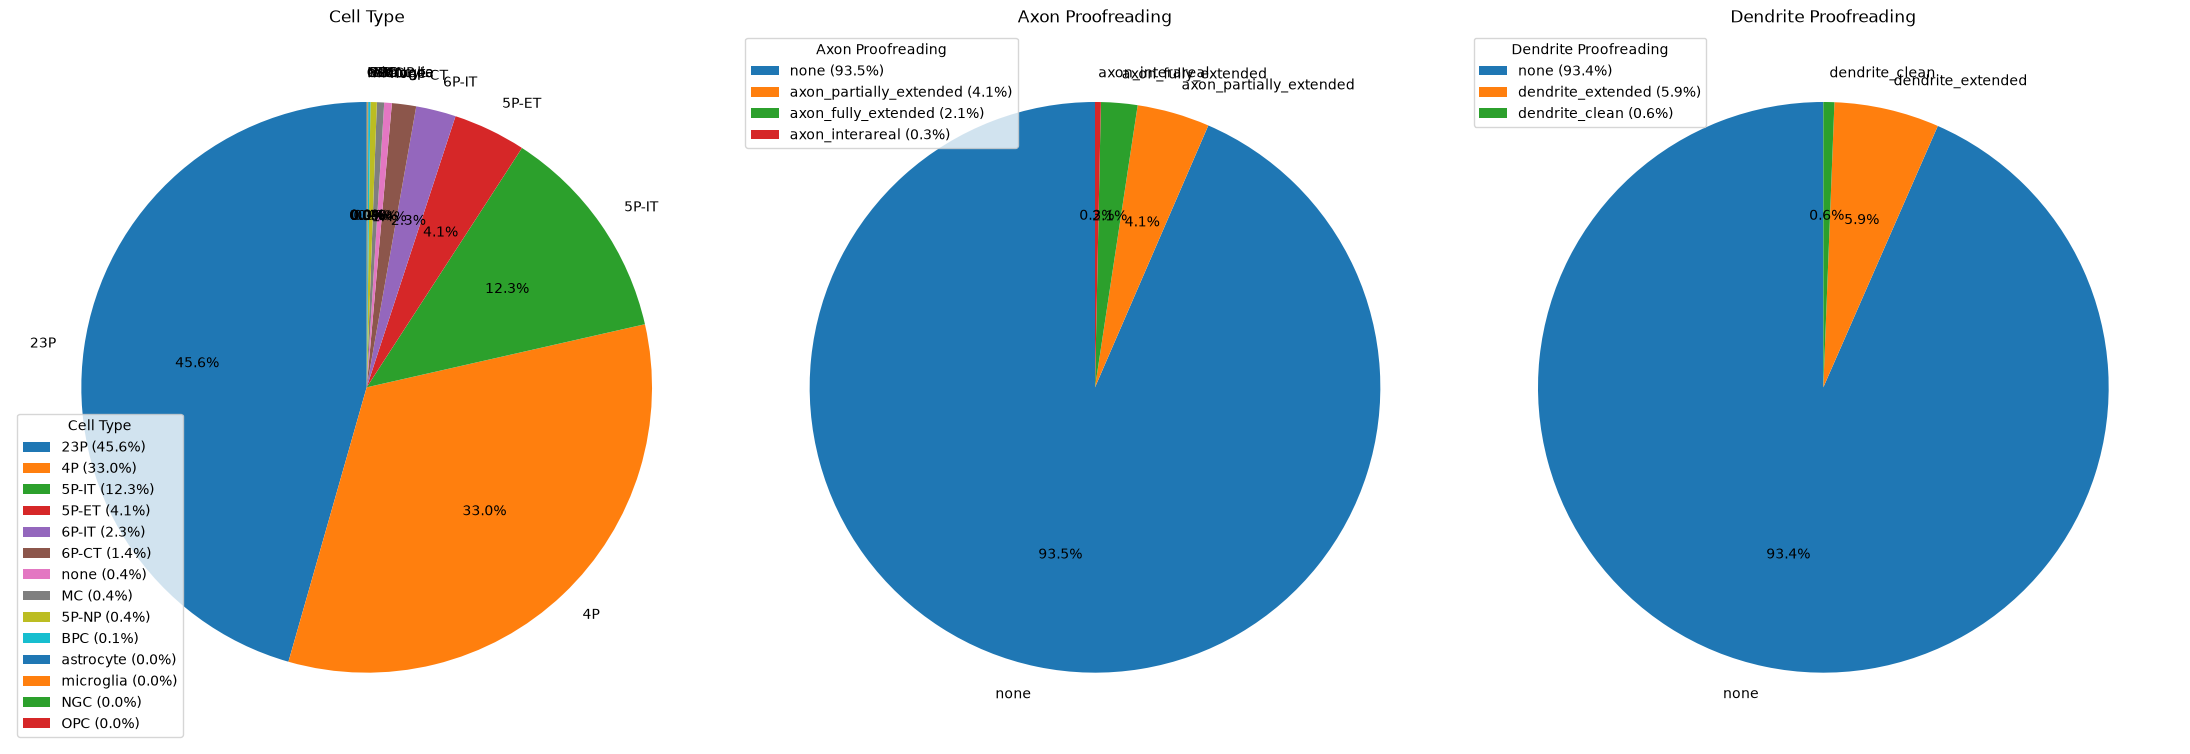

In [25]:
import matplotlib.pyplot as plt

cell_type_p = neurons_df["cell_type"].value_counts(normalize=True) * 100
axon_proof_p = neurons_df["axon_proof"].value_counts(normalize=True) * 100
dend_proof_p = neurons_df["dend_proof"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

neurons_df["cell_type"].fillna("none").astype(str).value_counts().plot.pie(
  ax=axes[0],
  ylabel="",
  autopct="%1.1f%%",
  startangle=90,
)
axes[0].set_title("Cell Type")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(
  handles,
  [f"{label} ({cell_type_p.get(label, 0):.1f}%)" for label in labels],
  title="Cell Type",
)

neurons_df["axon_proof"].fillna("none").value_counts().plot.pie(
  ax=axes[1],
  ylabel="",
  autopct="%1.1f%%",
  startangle=90,
)
axes[1].set_title("Axon Proofreading")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
  handles,
  [f"{label} ({axon_proof_p.get(label, 0):.1f}%)" for label in labels],
  title="Axon Proofreading",
)

neurons_df["dend_proof"].fillna("none").value_counts().plot.pie(
  ax=axes[2],
  ylabel="",
  autopct="%1.1f%%",
  startangle=90,
)
axes[2].set_title("Dendrite Proofreading")
handles, labels = axes[2].get_legend_handles_labels()
axes[2].legend(
  handles,
  [f"{label} ({dend_proof_p.get(label, 0):.1f}%)" for label in labels],
  title="Dendrite Proofreading",
)

plt.tight_layout()
plt.show()

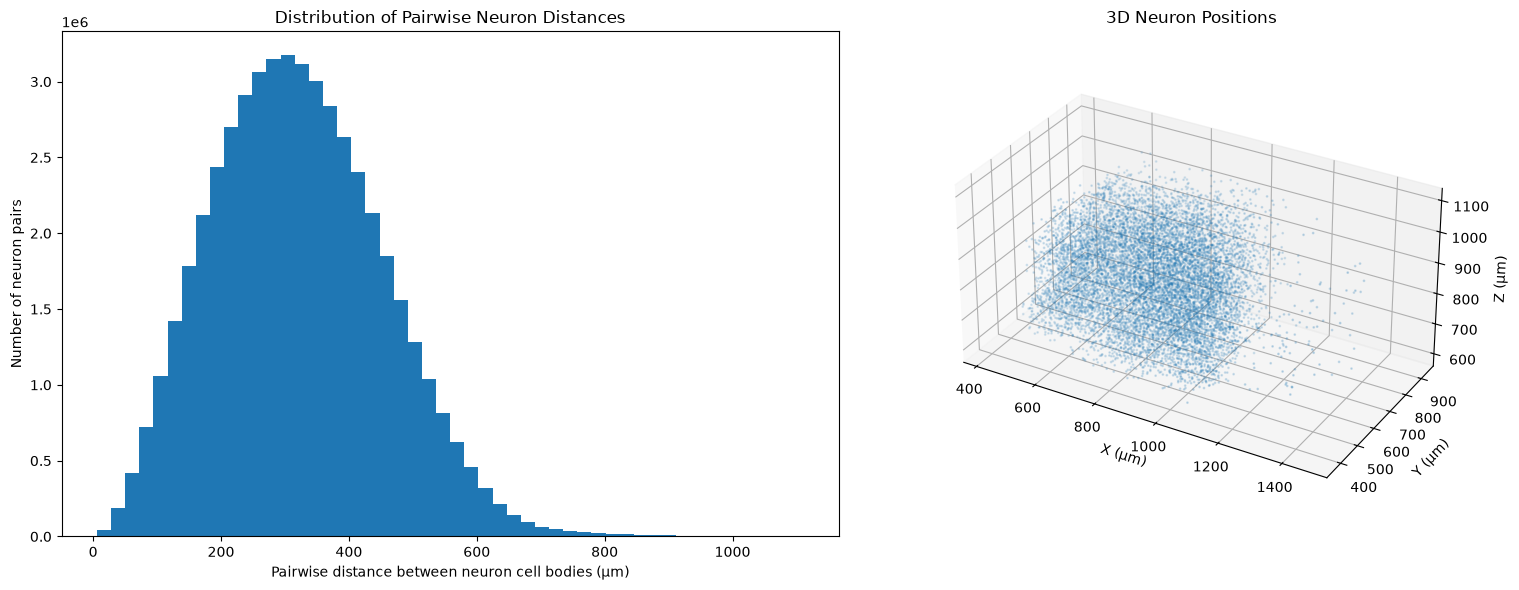

In [26]:
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

positions_df = neurons_df[["x", "y", "z"]].dropna()
positions = positions_df.to_numpy(dtype=float)

distances = pdist(positions, metric="euclidean")

fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(121)
ax1.hist(distances, bins=50)

ax1.set_xlabel("Pairwise distance between neuron cell bodies (µm)")
ax1.set_ylabel("Number of neuron pairs")
ax1.set_title("Distribution of Pairwise Neuron Distances")

ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(
  positions[:, 0],
  positions[:, 1],
  positions[:, 2],
  s=1,
  alpha=0.5,
)

ax2.set_xlabel("X (µm)")
ax2.set_ylabel("Y (µm)")
ax2.set_zlabel("Z (µm)")
ax2.set_title("3D Neuron Positions")

ax2.set_box_aspect([
  positions[:, 0].max() - positions[:, 0].min(),
  positions[:, 1].max() - positions[:, 1].min(),
  positions[:, 2].max() - positions[:, 2].min(),
])

plt.tight_layout()
plt.show()

# 3. Construct Synapse Lookup

We are going to build `synapses_df`, a general-purpose synapse information lookup. Here are the table headers:
| Key | Type | Description |
| - | - | - |
| `pre_id` | int | INDEX, the presynaptic neuron id |
| `post_id` | int | INDEX, the postsynaptic neuron id |
| `n` | int | the number of synapses, usable as the "strength" of a connection |

In [27]:
import os
import math

BATCH_SIZE = 100

ids = neurons_df.index.to_list()

cache_dir = f"cache/synapses/n{neurons_df.shape[0]}_bs{BATCH_SIZE}"
os.makedirs(cache_dir, exist_ok=True)

n_batches = math.ceil(neurons_df.shape[0] / BATCH_SIZE)
for batch_i in range(n_batches):
  file = os.path.join(cache_dir, f"b{batch_i}.parquet")
  if os.path.exists(file):
    print(f"Fetching batch {batch_i}/{n_batches}: SKIPPED, exists")
    continue
  start = batch_i * BATCH_SIZE
  stop = min((batch_i + 1) * BATCH_SIZE, neurons_df.shape[0])
  print(f"Fetching batch {batch_i}/{n_batches}: [{start}, {stop})...")
  pre_ids = ids[start:stop]
  post_ids = ids
  batch_df = client.materialize.synapse_query(
    pre_ids=pre_ids,
    post_ids=post_ids,
    remove_autapses=True,
    desired_resolution=[1]*3,
    split_positions=True,
  )
  batch_df.to_parquet(file)
  print(f"Fetched batch {batch_i}")

batch_dfs = []
for batch_i in range(n_batches):
  batch_df = pd.read_parquet(os.path.join(cache_dir, f"b{batch_i}.parquet"))
  batch_dfs.append(batch_df)

raw_synapses_df = pd.concat(batch_dfs, axis=0)
print(raw_synapses_df.columns.to_list())
display(raw_synapses_df.head())

Fetching batch 0/100: [0, 100)...
Fetched batch 0
Fetching batch 1/100: [100, 200)...
Fetched batch 1
Fetching batch 2/100: [200, 300)...
Fetched batch 2
Fetching batch 3/100: [300, 400)...
Fetched batch 3
Fetching batch 4/100: [400, 500)...
Fetched batch 4
Fetching batch 5/100: [500, 600)...
Fetched batch 5
Fetching batch 6/100: [600, 700)...
Fetched batch 6
Fetching batch 7/100: [700, 800)...
Fetched batch 7
Fetching batch 8/100: [800, 900)...
Fetched batch 8
Fetching batch 9/100: [900, 1000)...
Fetched batch 9
Fetching batch 10/100: [1000, 1100)...
Fetched batch 10
Fetching batch 11/100: [1100, 1200)...
Fetched batch 11
Fetching batch 12/100: [1200, 1300)...
Fetched batch 12
Fetching batch 13/100: [1300, 1400)...
Fetched batch 13
Fetching batch 14/100: [1400, 1500)...
Fetched batch 14
Fetching batch 15/100: [1500, 1600)...
Fetched batch 15
Fetching batch 16/100: [1600, 1700)...
Fetched batch 16
Fetching batch 17/100: [1700, 1800)...
Fetched batch 17
Fetching batch 18/100: [1800, 190

,id,created,superceded_id,valid,pre_pt_position_x,pre_pt_position_y,pre_pt_position_z,post_pt_position_x,post_pt_position_y,post_pt_position_z,ctr_pt_position_x,ctr_pt_position_y,ctr_pt_position_z,size,pre_pt_supervoxel_id,pre_pt_root_id,post_pt_supervoxel_id,post_pt_root_id
0,265606833,2020-11-04 06:48:59.036865+00:00,<NA>,True,960904,760168,809960,960600,759776,810040,960632,760032,810200,18432.0,97829872386522277,864691135765208374,97759503642373791,864691136297672475
1,245754551,2020-11-04 12:46:27.378664+00:00,<NA>,True,903008,698704,710480,903336,698552,710280,903096,698688,710480,1680.0,95787116885609259,864691136673575047,95857485629793223,864691136085205868
3,236245818,2020-11-04 06:49:11.546047+00:00,<NA>,True,890976,559768,945760,890824,559952,945960,890820,559964,945720,31876.0,95360232301137644,864691136489055762,95360301020631922,864691136907500142
4,158463423,2020-11-04 06:48:59.510128+00:00,<NA>,True,708400,584432,768960,708808,584344,769280,708656,584432,769200,1660.0,89098238099261545,864691135774461179,89168606843454772,864691135585662584
9,156164886,2020-11-04 07:15:04.596481+00:00,<NA>,True,696376,883136,852600,696592,882832,852880,696360,882920,852720,8752.0,88686058946272113,864691135765208374,88756427690463483,864691136380718037


In [28]:
synapses_df = (
  raw_synapses_df
  .groupby(["pre_pt_root_id", "post_pt_root_id"])
  .size()
  .rename("n")
  .to_frame()
)
synapses_df.index.names = ["pre_id", "post_id"]

print(synapses_df.columns.to_list())
print(synapses_df.shape)
display(synapses_df.head())

['n']
(267794, 1)


n
pre_id             post_id              
864691134884756730 864691135059358875  2
                   864691135210864064  1
                   864691135213620864  1
                   864691135441512776  1
                   864691135479370694  1

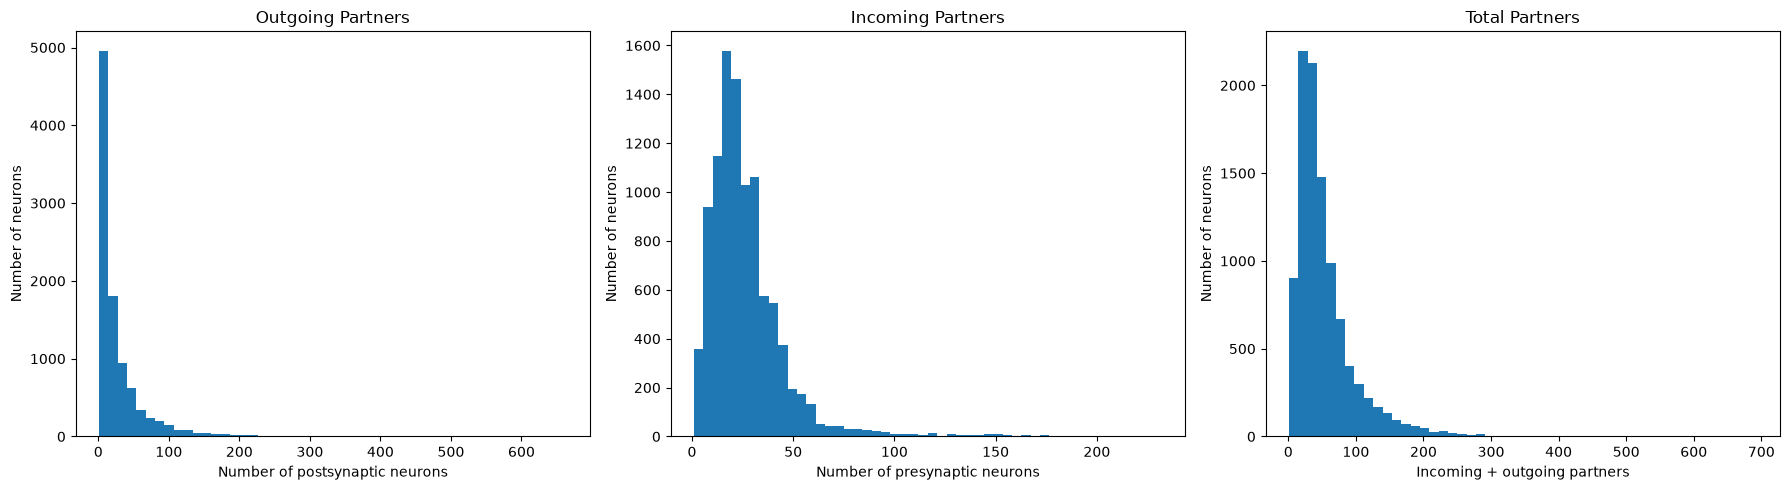

In [29]:
import matplotlib.pyplot as plt

pairs = synapses_df.reset_index()
posts_per_pre = pairs.groupby("pre_id")["post_id"].nunique()
pres_per_post = pairs.groupby("post_id")["pre_id"].nunique()
total_connections = posts_per_pre.add(pres_per_post, fill_value=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(posts_per_pre, bins=50)
axes[0].set_xlabel("Number of postsynaptic neurons")
axes[0].set_ylabel("Number of neurons")
axes[0].set_title("Outgoing Partners")

axes[1].hist(pres_per_post, bins=50)
axes[1].set_xlabel("Number of presynaptic neurons")
axes[1].set_ylabel("Number of neurons")
axes[1].set_title("Incoming Partners")

axes[2].hist(total_connections, bins=50)
axes[2].set_xlabel("Incoming + outgoing partners")
axes[2].set_ylabel("Number of neurons")
axes[2].set_title("Total Partners")

plt.tight_layout()
plt.show()

# 4. Baselines

These different baselines let us compare how well our trained model performs.

## 4.1. Distance-matched Baseline

This is just to see how well a Euclidian distance-based fares against the whole dataset.

We have a couple considerations to make here.
1. Most neuron pairs are not synaptic. A high accuracy score could simply mean it classifies a lot of neurons as non-synaptic.
2. Distance-matched analysis is guaranteed to result in 50% accuracy, since the distance distributions match.

We will also create the distance-matching here.

In [66]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist

ids_np = np.array(ids)

positions_df = neurons_df[["x", "y", "z"]].dropna()
positions = position_df.to_numpy(dtype=float)
distances = pdist(positions, metric="euclidean")

pair_i, pair_j = np.triu_indices(len(ids_np), k=1)
pairs_df = pd.DataFrame({
  "id1": ids_np[pair_i],
  "id2": ids_np[pair_j],
  "distance": distances,
})
synapse_pairs = set(synapses_df.index.to_list())

pairs_df["has_synapse"] = [
  (a, b) in synapse_pairs or (b, a) in synapse_pairs
  for a, b in zip(pairs_df["id1"], pairs_df["id2"])
]

nonsyn_distances = pairs_df.loc[~pairs_df["has_synapse"], "distance"].to_numpy(dtype=float)
syn_distances = pairs_df.loc[pairs_df["has_synapse"], "distance"].to_numpy(dtype=float)

In [ ]:
values = np.sort(np.unique(np.concatenate([syn_distances, nonsyn_distances])))
thresholds = (values[:-1] + values[1:]) / 2

syn_left = np.searchsorted(np.sort(syn_distances), thresholds, side="right") / len(syn_distances)
nonsyn_right = (len(nonsyn_distances) - np.searchsorted(np.sort(nonsyn_distances), thresholds, side="right")) / len(nonsyn_distances)

score = (syn_left + nonsyn_right) / 2

best_idx = np.argmax(score)
best_distance = thresholds[best_idx]

print(f"Best distance: {best_distance:.2f}μm")

d_thresh=  213.56μm
syn_A=     73.899%
nonsyn_A=  77.815%
accuracy=  75.857%


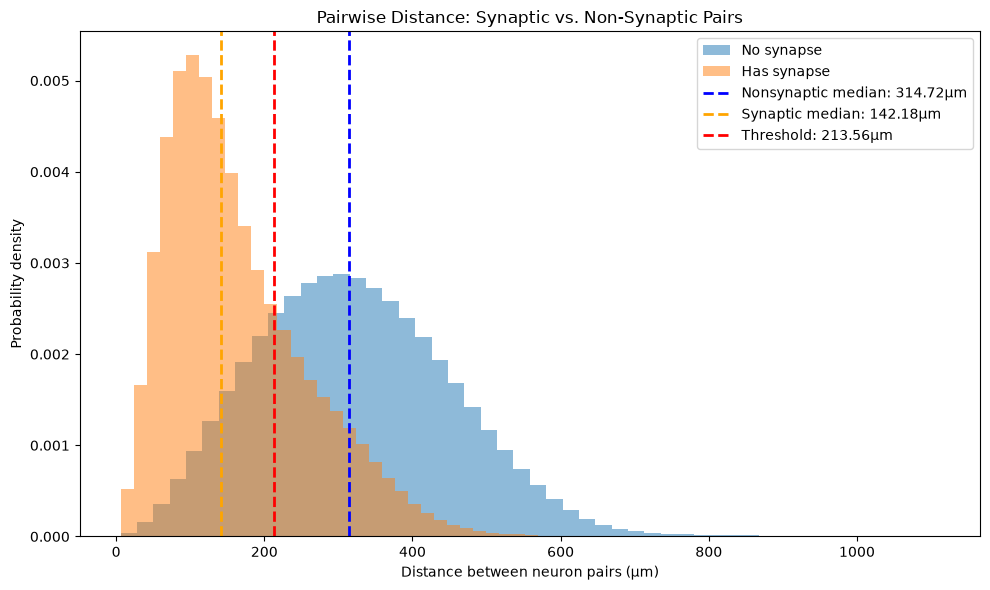

In [68]:
import numpy as np
import matplotlib.pyplot as plt

nonsyn_distances_median = np.median(nonsyn_distances)
syn_distances_median = np.median(syn_distances)

plt.figure(figsize=(10, 6))

plt.hist(
  nonsyn_distances,
  bins=50,
  density=True,
  alpha=0.5,
  label="No synapse",
)

plt.hist(
  syn_distances,
  bins=50,
  density=True,
  alpha=0.5,
  label="Has synapse",
)

plt.axvline(
  nonsyn_distances_median,
  color="blue",
  linestyle="--",
  linewidth=2,
  label=f"Nonsynaptic median: {nonsyn_distances_median:.2f}μm",
)

plt.axvline(
  syn_distances_median,
  color="orange",
  linestyle="--",
  linewidth=2,
  label=f"Synaptic median: {syn_distances_median:.2f}μm",
)

plt.axvline(
  best_distance,
  color="red",
  linestyle="--",
  linewidth=2,
  label=f"Threshold: {best_distance:.2f}μm",
)

plt.xlabel("Distance between neuron pairs (µm)")
plt.ylabel("Probability density")
plt.title("Pairwise Distance: Synaptic vs. Non-Synaptic Pairs")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy.spatial.distance import cdist

id_to_idx = {neuron_id: i for i, neuron_id in enumerate(positions_df.index)}
pre_idx = synapses_df.index.get_level_values("pre_id").map(id_to_idx).to_numpy(dtype=int)
post_idx = synapses_df.index.get_level_values("post_id").map(id_to_idx).to_numpy(dtype=int)

distances_mat = cdist(positions, positions, metric="euclidean")

y_true = np.zeros(distances_mat.shape, dtype=np.uint8)
y_true[pre_idx, post_idx] = 1
np.fill_diagonal(y_true, 0)

In [76]:
import numpy as np
from sklearn.metrics import (
  classification_report,
  precision_score, recall_score, f1_score,
  accuracy_score, balanced_accuracy_score,
)

y_pred = distances_mat <= best_distance
np.fill_diagonal(y_true, 0)

tp = np.count_nonzero(y_pred & y_true)
fp = np.count_nonzero(y_pred & ~y_true)
tn = np.count_nonzero(~y_pred & ~y_true)
fn = np.count_nonzero(~y_pred & y_true)

precision = precision_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
recall = recall_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
f1 = f1_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
accuracy = accuracy_score(y_true.ravel(), y_pred.ravel())
balanced_accuracy = balanced_accuracy_score(y_true.ravel(), y_pred.ravel())
specificity = tn / (tn + fp) if tn + fp else 0.0

print(f"Threshold:          {best_distance:.2f}µm")
print(f"TP:                 {tp:,}")
print(f"FP:                 {fp:,}")
print(f"TN:                 {tn:,}")
print(f"FN:                 {fn:,}")
print(f"Precision:          {precision:.4f}")
print(f"Recall/sensitivity: {recall:.4f}")
print(f"Specificity:        {specificity:.4f}")
print(f"F1:                 {f1:.4f}")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Balanced accuracy:  {balanced_accuracy:.4f}")
print(classification_report(
  y_true.ravel(),
  y_pred.ravel(),
  labels=[False, True],
  target_names=["Not connected", "Connected"],
  zero_division=0,
  digits=4,
))

Threshold:          213.56µm
TP:                 198,288
FP:                 22,269,704
TN:                 77,462,502
FN:                 69,506
Precision:          0.0088
Recall/sensitivity: 0.7404
Specificity:        0.7767
F1:                 0.0174
Accuracy:           0.7766
Balanced accuracy:  0.7586
               precision    recall  f1-score   support

Not connected     0.9991    0.7767    0.8740  99732206
    Connected     0.0088    0.7404    0.0174    267794

     accuracy                         0.7766 100000000
    macro avg     0.5040    0.7586    0.4457 100000000
 weighted avg     0.9965    0.7766    0.8717 100000000



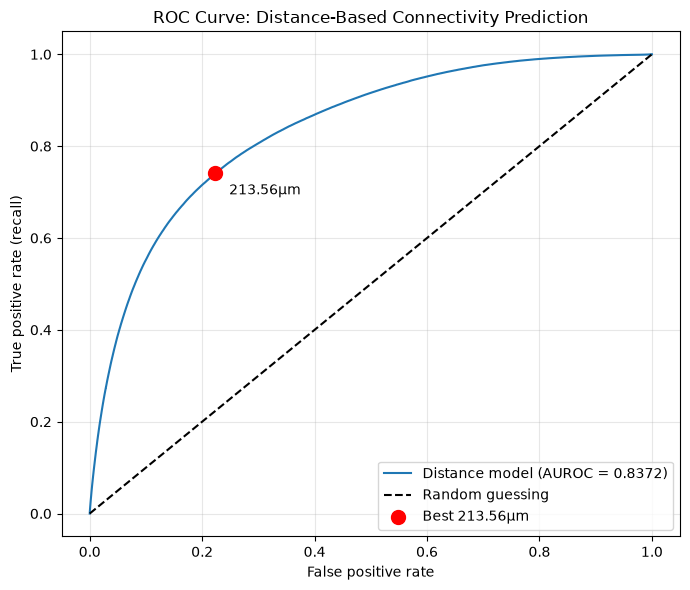

AUROC: 0.8372


In [74]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

n = distances_mat.shape[0]
mask = ~np.eye(n, dtype=bool)

y_true_flat = y_true[mask]
scores = -distances_mat[mask]

fpr, tpr, thresholds = roc_curve(y_true_flat, scores)
auroc = roc_auc_score(y_true_flat, scores)

idx = np.argmin(np.abs(thresholds + best_distance))

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Distance model (AUROC = {auroc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")

plt.scatter(
  fpr[idx], tpr[idx],
  color="red", s=100, zorder=5,
  label=f"Best {best_distance:.2f}µm",
)
plt.annotate(
  f"{best_distance:.2f}µm",
  (fpr[idx], tpr[idx]),
  xytext=(10, -15),
  textcoords="offset points",
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC Curve: Distance-Based Connectivity Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"AUROC: {auroc:.4f}")

In [78]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
bin_width = 5

pos_i, pos_j = np.where(y_true)
pos_dist = distances_mat[pos_i, pos_j]

pos_bins = np.floor(pos_dist / bin_width).astype(int)

n = y_true.shape[0]
neg_mask = ~y_true.copy()
np.fill_diagonal(neg_mask, False)

neg_i, neg_j = np.where(neg_mask)
neg_dist = distances_mat[neg_i, neg_j]
neg_bins = np.floor(neg_dist / bin_width).astype(int)

matched_pos, matched_neg = [], []

for b in np.unique(pos_bins):
  p = np.flatnonzero(pos_bins == b)
  q = np.flatnonzero(neg_bins == b)
  if len(q) == 0:
    continue
  k = min(len(p), len(q))
  p_selected = rng.choice(p, size=k, replace=False)
  q_selected = rng.choice(q, size=k, replace=False)
  matched_pos.extend(p_selected)
  matched_neg.extend(q_selected)

matched_pos = np.asarray(matched_pos, dtype=int)
matched_neg = np.asarray(matched_neg, dtype=int)

matched_df = pd.concat([
  pd.DataFrame({
    "pre_id": neurons_df.index[pos_i[matched_pos]],
    "post_id": neurons_df.index[pos_j[matched_pos]],
    "distance": pos_dist[matched_pos],
    "connected": 1,
  }),
  pd.DataFrame({
    "pre_id": neurons_df.index[neg_i[matched_neg]],
    "post_id": neurons_df.index[neg_j[matched_neg]],
    "distance": neg_dist[matched_neg],
    "connected": 0,
  }),
], ignore_index=True)

print(f"Matched positives: {(matched_df["connected"] == 1).sum():,}")
print(f"Matched negatives: {(matched_df["connected"] == 0).sum():,}")

Matched positives: 267,794
Matched negatives: 267,794
